# Environmental Footprints of Housing
This code calculates environmental footprints of housing under a given set of energy use, energy technology, housing size of different building types, and transport use in relation to location and income.

For the analysis of current housing in NL the following datasets are needed:
- Set of assumptions: CBS microdata output
- Material use per building types
- Material use per solar PV capacity
- Material use per heat pump
- District heat source distribution
- Fuel use per pkm
- Infrastructural material use per pkm

In [28]:
# data processing modules
import pandas as pd
import numpy as np

# data visualisation modules
import matplotlib.pyplot as plt
import plotly.graph_objects as go
import plotly.express as px
import seaborn as sns

# Display options
pd.options.display.float_format = '{:,.2f}'.format #limits printed decimal points to two
#pd.reset_option('^display.', silent=True) #option to reset the previous display option

In [29]:
def multiply_subcategories(df_detail, df_aggregate):
    """ 
    Multiplies a detailed dataframe with an aggregated dataframe

    Returns a detailed dataframe in which each each row is multiplied with the corresponding row in the aggregated dataframe
    Index level 0 of the detailed dataframe must match the index of the aggregated dataframe.
    
    Args:
        df_detail: multi-indexed dataframe of length a*b and width c
        df_aggregate: dataframe of length a and width c
    
    Returns: 
        pandas.DataFrame: Detailed dataframe of length a*b and width c in which each each row is multiplied with the corresponding row in the aggregated dataframe
        """
    df_new = pd.DataFrame(index=df_detail.index, columns=df_detail.columns)
    for i in df_aggregate.index:
        df_new.update(df_detail.xs(i, axis=0, level=0, drop_level=False).mul(df_aggregate.loc[i], axis=1))
        
    return df_new


## Foreground System: Calculate and Harmonize Direct Material, Fuel & Electricity Use

### Set of Assumptions
- configure assumptions
- import the CBS file

In [30]:
# Configurations
scenario = 'current'
material_buildings_source = 'Oorschot-MPG' #alternative 'Oorschot' contains a different grouping (semi-detached and detached together, instead of row and semi-detached)
material_solarpv_source = 'ecoinvent'
material_heatpump_source = 'ecoinvent'
material_pkminfra_source = None
fuel_pkm_source = None
fuel_districtheating_source = None

# File import
if scenario == "current":
    use = pd.read_excel(
        "data_input/output/income typology construction density distance privacy 2019.xlsx",
        #"data_input/output/income typology construction density distance privacy 2019.xlsx",
        index_col=[0,1,2,3,4],
        header=[0],
    )

    mobility = pd.read_excel(
            "data_input/output/income density distance privacy odin 2019.xlsx",
           #"data_input/output/income density distance privacy odin 2019.xlsx",
            index_col=[0,1,2],
            header=[0],
        )

    # add transport use and vehicles per household to other variables, assumption: households with similar income, surrounding population density and distance to train station show similar mobility behaviour irrespective of building type or building age
    use_pkm = mobility['car_trips']*mobility['dist_carpp'] / mobility['n_hhd']#pkm per year per household
    use_pkm.name = 'car_pkm'
    use = use.join(use_pkm, on=['inc_lab','density_lab', 'distance_train_lab'])

    use_pkm = mobility['transit_trips']*mobility['dist_transit'] / mobility['n_hhd'] #pkm per year per household
    use_pkm.name = 'transit_pkm'
    use = use.join(use_pkm, on=['inc_lab','density_lab', 'distance_train_lab'])

    use_pkm = mobility['walk_trips']*mobility['dist_walk'] / mobility['n_hhd'] #pkm per year per household
    use_pkm.name = 'walk_pkm'
    use = use.join(use_pkm, on=['inc_lab','density_lab', 'distance_train_lab'])

    use_pkm = mobility['cycle_trips']*mobility['dist_cycle'] / mobility['n_hhd'] #pkm per year per household
    use_pkm.name = 'cycle_pkm'
    use = use.join(use_pkm, on=['inc_lab','density_lab', 'distance_train_lab'])

    use = use.join(mobility['car_hhd'], on=['inc_lab','density_lab', 'distance_train_lab']) #cars per household

In [31]:
use

inc_decile  \
inc_lab             typology_lab              const_lab density_lab distance_train_lab               
decile 1 (poorest)  detached (vrijstaand)     pre 1945  very urban  nearest quintile             1   
                                                                    2nd quintile                 1   
                                                                    3nd quintile                 1   
                                                                    4nd quintile                 1   
                                                                    furthest quintile            1   
...                                                                                            ...   
decile 10 (richest) multiple fam (meergezins) 2006-2022 rural       nearest quintile            10   
                                                                    2nd quintile                10   
                                                                    3nd quintile                10   
                                                                    4nd quintile                10   
                                                                    furthest quintile           10   

                                                                                        typology4_2019  \
inc_lab             typology_lab              const_lab density_lab distance_train_lab                   
decile 1 (poorest)  detached (vrijstaand)     pre 1945  very urban  nearest quintile                 1   
                                                                    2nd quintile                     1   
                                                                    3nd quintile                     1   
                                                                    4nd quintile                     1   
                                                                    furthest quintile                1   
...                                                                                                ...   
decile 10 (richest) multiple fam (meergezins) 2006-2022 rural       nearest quintile                 4   
                                                                    2nd quintile                     4   
                                                                    3nd quintile                     4   
                                                                    4nd quintile                     4   
                                                                    furthest quintile                4   

                                                                                        const_cat2019  \
inc_lab             typology_lab              const_lab density_lab distance_train_lab                  
decile 1 (poorest)  detached (vrijstaand)     pre 1945  very urban  nearest quintile                1   
                                                                    2nd quintile                    1   
                                                                    3nd quintile                    1   
                                                                    4nd quintile                    1   
                                                                    furthest quintile               1   
...                                                                                               ...   
decile 10 (richest) multiple fam (meergezins) 2006-2022 rural       nearest quintile                6   
                                                                    2nd quintile                    6   
                                                                    3nd quintile                    6   
                                                                    4nd quintile                    6   
                                                                    furthest quintile               6   

                

In [32]:
use[use['n_heatpump2019'].notna()].index.get_level_values(1).value_counts()

multiple fam (meergezins)                  124
semi-detached (2-1 kap) / corner (hoek)      1
Name: typology_lab, dtype: int64

In [33]:
np.allclose(use['size2019_w1']/use['mean_hhd'], use['size2019_w1']*use['n_hhd']/use['n_hhdmem2019'], equal_nan=True)

True

In [34]:
(use['size2019_w1']*use['n_hhd']) / (use['size2019pp_w1']*use['n_hhdmem2019']) #use the size per household to stay consistent with total floor space

inc_lab              typology_lab               const_lab  density_lab  distance_train_lab
decile 1 (poorest)   detached (vrijstaand)      pre 1945   very urban   nearest quintile     0.92
                                                                        2nd quintile         0.91
                                                                        3nd quintile         0.83
                                                                        4nd quintile         1.33
                                                                        furthest quintile     NaN
                                                                                             ... 
decile 10 (richest)  multiple fam (meergezins)  2006-2022  rural        nearest quintile     1.00
                                                                        2nd quintile         0.78
                                                                        3nd quintile         0.90
                           

In [35]:
use.index.levels[2]

Index(['1946-1964', '1965-1974', '1975-1991', '1992-2005', '2006-2022',
       'pre 1945'],
      dtype='object', name='const_lab')

<AxesSubplot: xlabel='inc_lab'>

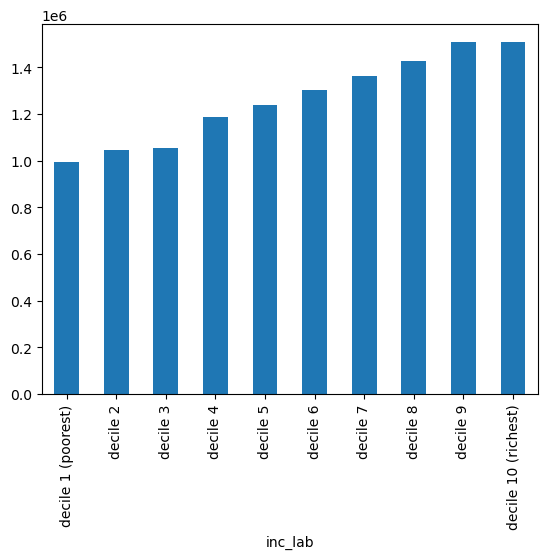

In [36]:
use['n_adultmem2019'].groupby(level=0, sort=False).sum().plot(kind='bar') 

In [37]:
use['n_heatpump2019'].sum()

3655.0

In [38]:
use['n_cityheating2019'].sum()

407905.0

In [39]:
(use['size2019_w1']*use['n_hhd']).sum()

846986904.185009

### Service inequality visualisations: floor area, electricity, pkm

#### Floor area

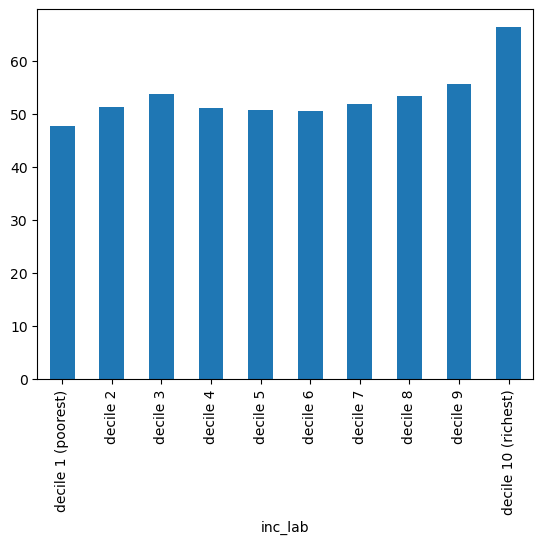

In [40]:
#floor area per income level
use_m2_total_inc = (use['size2019_w1']*use['n_hhd']).groupby(level=0, sort=False).sum() #m2 total in each group summed by income level
use_cap_total_inc = use['n_hhdmem2019'].groupby(level=0, sort=False).sum() #no. of people in each group summed by income level
use_m2_per_cap_inc = use_m2_total_inc / use_cap_total_inc #m2/cap in each income group
use_m2_per_cap_inc.plot(kind='bar') #per person
"""interpretation: especially the highest income decile has considerably more floor area available than the vast majority"""

#floor area per income level and building type
use_m2_total_inc_type = (use['size2019_w1']*use['n_hhd']).groupby(level=[0,1], sort=False).sum() #m2 total in each group summed by income level
use_cap_total_inc_type = use['n_hhdmem2019'].groupby(level=[0,1], sort=False).sum() #no. of people in each group summed by income level
use_m2_per_cap_inc_type = use_m2_total_inc_type / use_cap_total_inc_type #m2/cap in each income group

#preparing the dataframes for plotting
df = use_m2_per_cap_inc
df2=use_m2_per_cap_inc_type.rename('value').to_frame()
df2['n_hhd'] = use['n_hhd'].groupby(level=[0,1], sort=False).sum()
df2 = df2.reset_index()

#plot
colors = ['#000000', #construction
                            '#fe6100', #buildings                                              
                                        '#648fff', #roads
                                        '#785ef0', #railways
                                        '#ffb000', #electricity
                                        '#808080', #other civil engineering
                                        '#000000', #construction
                                        ]
fig = px.bar(df, x=df.values, y=df.index,  
             labels={'x':'m2 floor area per capita', 'inc_lab':'household income level'}, 
             template='simple_white', 
             color_discrete_sequence=colors) 
fig.update_layout(width=1000, height=500, 
                      #xaxis_tickformat = '.0%',
                      font=dict(size=18),
                      bargap=0.9,
                      legend=dict(
        orientation="h",
        #entrywidth=70,
        yanchor="bottom",
        y=1.02,
        xanchor="left",
        x=-0.25,
    ))

df2=use_m2_per_cap_inc_type.rename('value').to_frame()
df2['n_hhd'] = use['n_hhd'].groupby(level=[0,1], sort=False).sum()

for i in df2.index.levels[1].to_list():
    df_plot = df2.xs(i, level=1)
    fig.add_trace(go.Scatter(
            y=df_plot.index, 
            x=df_plot['value'],
            mode='markers',
            name=i,
            marker=dict(size=df_plot['n_hhd'],
                        sizemode='area',
                        sizeref=4*max(df2['n_hhd'])/(40.**2),
                        sizemin=4,
                        #color=10*[0, 1, 2, 3],
                        ),
            showlegend=True
        ))

fig.write_image('visualisations/bubblechart_m2_per_cap_inc_type.png', scale=3)
fig.show()


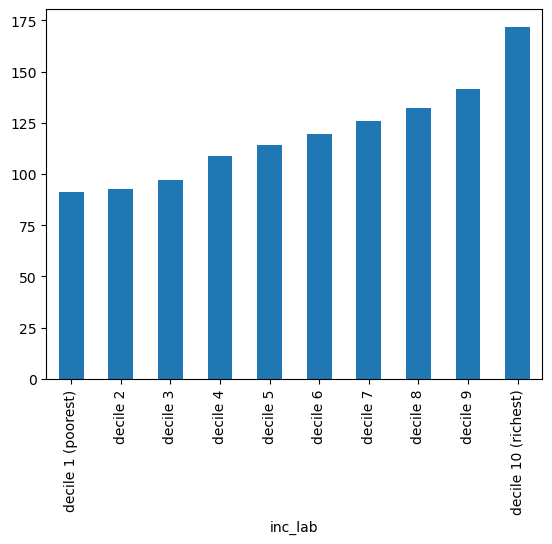

In [41]:
#floor area per income level
use_m2_total_inc = (use['size2019_w1']*use['n_hhd']).groupby(level=0, sort=False).sum() #m2 total in each group summed by income level
use_cap_total_inc = use['n_hhd'].groupby(level=0, sort=False).sum() #no. of people in each group summed by income level
use_m2_per_cap_inc = use_m2_total_inc / use_cap_total_inc #m2/cap in each income group
use_m2_per_cap_inc.plot(kind='bar') #per person
"""interpretation: especially the highest income decile has considerably more floor area available than the vast majority"""

#floor area per income level and building type
use_m2_total_inc_type = (use['size2019_w1']*use['n_hhd']).groupby(level=[0,1], sort=False).sum() #m2 total in each group summed by income level
use_cap_total_inc_type = use['n_hhd'].groupby(level=[0,1], sort=False).sum() #no. of people in each group summed by income level
use_m2_per_cap_inc_type = use_m2_total_inc_type / use_cap_total_inc_type #m2/cap in each income group

#preparing the dataframes for plotting
df = use_m2_per_cap_inc
df2=use_m2_per_cap_inc_type.rename('value').to_frame()
df2['n_hhd'] = use['n_hhd'].groupby(level=[0,1], sort=False).sum()
df2 = df2.reset_index()

#plot
colors = ['#000000', #construction
                            '#fe6100', #buildings                                              
                                        '#648fff', #roads
                                        '#785ef0', #railways
                                        '#ffb000', #electricity
                                        '#808080', #other civil engineering
                                        '#000000', #construction
                                        ]
fig = px.bar(df, x=df.values, y=df.index,  
             labels={'x':'m2 floor area per household', 'inc_lab':'household income level'}, 
             template='simple_white', 
             color_discrete_sequence=colors) 
fig.update_layout(width=1000, height=500, 
                      #xaxis_tickformat = '.0%',
                      font=dict(size=18),
                      bargap=0.9,
                      legend=dict(
        orientation="h",
        #entrywidth=70,
        yanchor="bottom",
        y=1.02,
        xanchor="left",
        x=-0.25,
    ))

df2=use_m2_per_cap_inc_type.rename('value').to_frame()
df2['n_hhd'] = use['n_hhd'].groupby(level=[0,1], sort=False).sum()

for i in df2.index.levels[1].to_list():
    df_plot = df2.xs(i, level=1)
    fig.add_trace(go.Scatter(
            y=df_plot.index, 
            x=df_plot['value'],
            mode='markers',
            name=i,
            marker=dict(size=df_plot['n_hhd'],
                        sizemode='area',
                        sizeref=4*max(df2['n_hhd'])/(40.**2),
                        sizemin=4,
                        #color=10*[0, 1, 2, 3],
                        ),
            showlegend=True
        ))

fig.write_image('visualisations/bubblechart_m2_per_hhd_inc_type.png', scale=3)
fig.show()

'interpretation: highest income group occupies almost 2 times as much space as lowest income group;\n    this is due to the increasing household size (especially that of adultmembers, see graph below), \n    so only very little variation in floor space per capita is correlated with income level (only the top10%)'

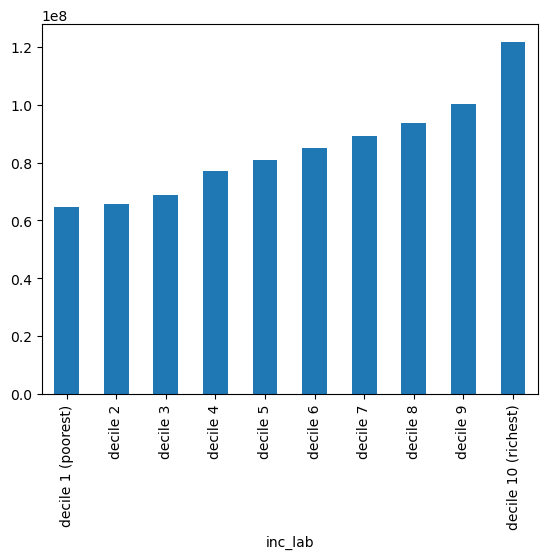

In [42]:
use_m2_total_inc.plot(kind='bar') # total floor area in each group
"""interpretation: highest income group occupies almost 2 times as much space as lowest income group;
    this is due to the increasing household size (especially that of adultmembers, see graph below), 
    so only very little variation in floor space per capita is correlated with income level (only the top10%)"""
#TODO: change to hourglass plot

<AxesSubplot: xlabel='inc_lab'>

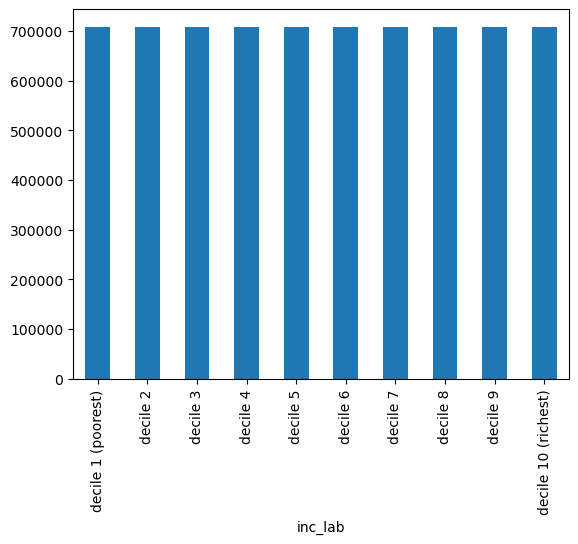

In [43]:
use_cap_total_inc.plot(kind='bar')

'interpretation: household size (especially adult members) increases with income level (exception when including children: lowest two levels because of single-parents), \nbut without strong correlation with the floor area per capita'

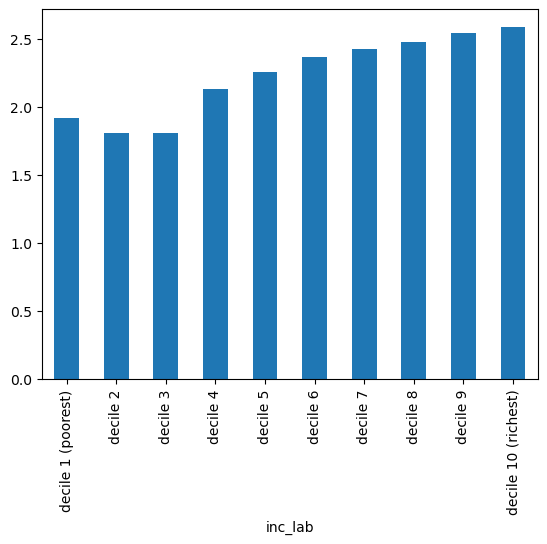

In [44]:
use_cap_total_inc = use['n_hhdmem2019'].groupby(level=0, sort=False).sum() #no. of people in each group summed by income level
use_hhd_total_inc = use['n_hhd'].groupby(level=0, sort=False).sum() #no. of households in each group summed by income level
use_cap_per_hhd_inc = use_cap_total_inc/use_hhd_total_inc 
use_cap_per_hhd_inc.plot(kind='bar')
"""interpretation: household size (especially adult members) increases with income level (exception when including children: lowest two levels because of single-parents), 
but without strong correlation with the floor area per capita"""

'interpretation: whether people live in a detached or multi-dwelling building is more indicative of the floor area per capita than their income; the higher floor area among the higher income deciles seems to be related to the type of building people live in rather than affording larger dwellings in the same category of building'

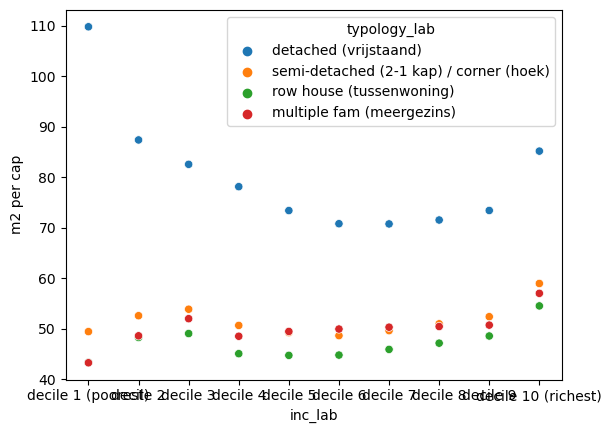

In [45]:
use_m2_total_inc = (use['size2019_w1']*use['n_hhd']).groupby(level=[0,1], sort=False).sum() #m2 total in each group summed by income level
use_cap_total_inc = use['n_hhdmem2019'].groupby(level=[0,1], sort=False).sum() #no. of people in each group summed by income level
use_m2_per_cap_inc = use_m2_total_inc / use_cap_total_inc #m2/cap in each income group
use_m2_per_cap_inc
df_plot = use_m2_per_cap_inc.rename('m2 per cap').reset_index()
sns.scatterplot(x='inc_lab', y='m2 per cap', data=df_plot, hue='typology_lab')
"""interpretation: whether people live in a detached or multi-dwelling building is more indicative of the floor area per capita than their income; the higher floor area among the higher income deciles seems to be related to the type of building people live in rather than affording larger dwellings in the same category of building"""
#TODO: plot this as bubble plot with size of dot indicating number of households or people in each group

'interpretation: whether people live on the countryside or urban seems to be more indicative for floor area than the income group, although the income group also follows a surprisingly coherent pattern across the urban-rural gradient'

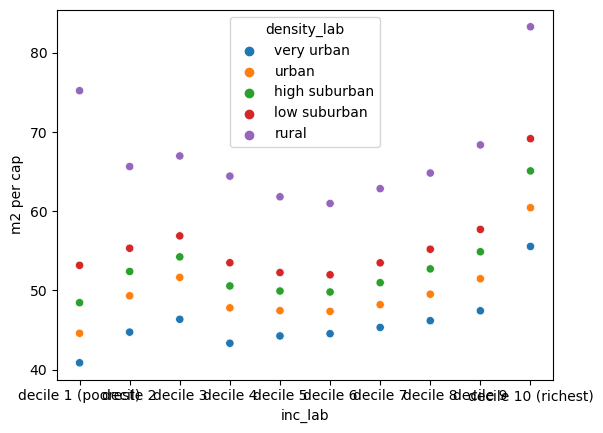

In [46]:
use_m2_total_inc = (use['size2019_w1']*use['n_hhd']).groupby(level=[0,3], sort=False).sum() #m2 total in each group summed by income level
use_cap_total_inc = use['n_hhdmem2019'].groupby(level=[0,3], sort=False).sum() #no. of people in each group summed by income level
use_m2_per_cap_inc = use_m2_total_inc / use_cap_total_inc #m2/cap in each income group
use_m2_per_cap_inc
df_plot = use_m2_per_cap_inc.rename('m2 per cap').reset_index()
sns.scatterplot(x='inc_lab', y='m2 per cap', data=df_plot, hue='density_lab')
"""interpretation: whether people live on the countryside or urban seems to be more indicative for floor area than the income group, although the income group also follows a surprisingly coherent pattern across the urban-rural gradient"""

'building type seems to be more indicative of floor area than the urban-rural gradient, although rural is in each category more floor space intensive than urban buildings of the same type'

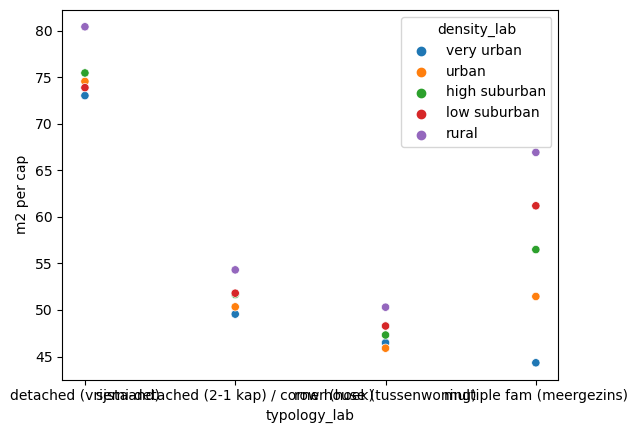

In [47]:
use_m2_total_inc = (use['size2019_w1']*use['n_hhd']).groupby(level=[1,3], sort=False).sum() #m2 total in each group summed by income level
use_cap_total_inc = use['n_hhdmem2019'].groupby(level=[1,3], sort=False).sum() #no. of people in each group summed by income level
use_m2_per_cap_inc = use_m2_total_inc / use_cap_total_inc #m2/cap in each income group
use_m2_per_cap_inc
df_plot = use_m2_per_cap_inc.rename('m2 per cap').reset_index()
sns.scatterplot(x='typology_lab', y='m2 per cap', data=df_plot, hue='density_lab')
"""building type seems to be more indicative of floor area than the urban-rural gradient, although rural is in each category more floor space intensive than urban buildings of the same type"""

'similar to urban-rural'

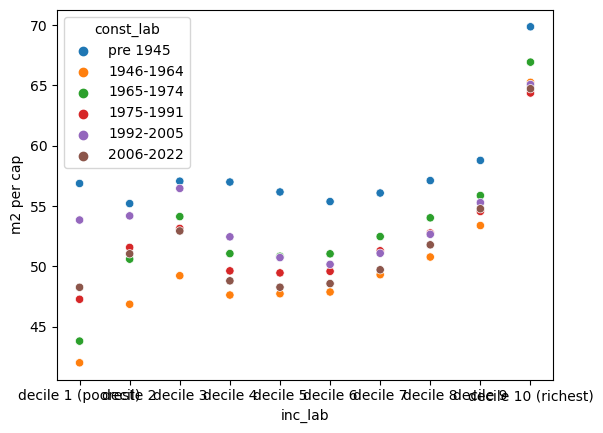

In [48]:
use_m2_total_inc = (use['size2019_w1']*use['n_hhd']).groupby(level=[0,2], sort=False).sum() #m2 total in each group summed by income level
use_cap_total_inc = use['n_hhdmem2019'].groupby(level=[0,2], sort=False).sum() #no. of people in each group summed by income level
use_m2_per_cap_inc = use_m2_total_inc / use_cap_total_inc #m2/cap in each income group
use_m2_per_cap_inc
df_plot = use_m2_per_cap_inc.rename('m2 per cap').reset_index()
sns.scatterplot(x='inc_lab', y='m2 per cap', data=df_plot, hue='const_lab')
"""similar to urban-rural"""

<AxesSubplot: xlabel='typology_lab', ylabel='m2 per cap'>

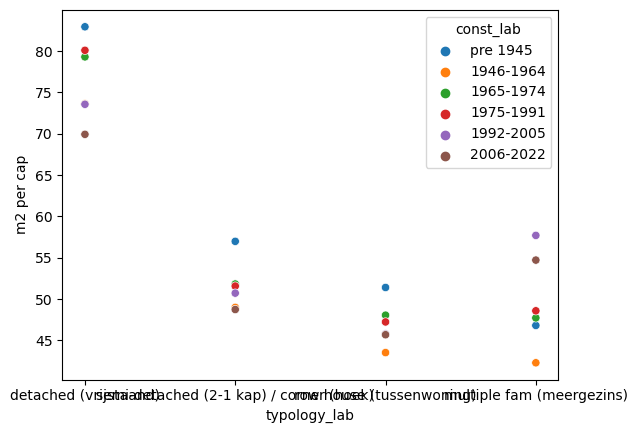

In [49]:
use_m2_total_inc = (use['size2019_w1']*use['n_hhd']).groupby(level=[1,2], sort=False).sum() #m2 total in each group summed by income level
use_cap_total_inc = use['n_hhdmem2019'].groupby(level=[1,2], sort=False).sum() #no. of people in each group summed by income level
use_m2_per_cap_inc = use_m2_total_inc / use_cap_total_inc #m2/cap in each income group
use_m2_per_cap_inc
df_plot = use_m2_per_cap_inc.rename('m2 per cap').reset_index()
sns.scatterplot(x='typology_lab', y='m2 per cap', data=df_plot, hue='const_lab')

#### Gas / space heating

'interpretation: especially the highest income decile has considerably more gas consumption per capita than the vast majority'

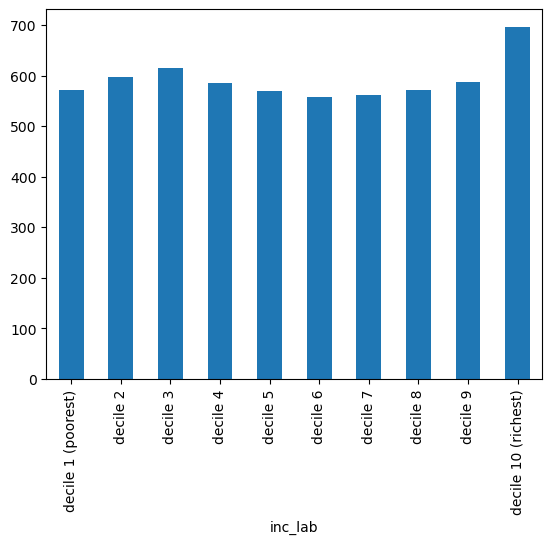

In [50]:
use_m2_total_inc = (use['gas2019']*use['n_hhd']).groupby(level=0, sort=False).sum() #m2 total in each group summed by income level
use_cap_total_inc = use['n_hhdmem2019'].groupby(level=0, sort=False).sum() #no. of people in each group summed by income level
use_m2_per_cap_inc = use_m2_total_inc / use_cap_total_inc #m2/cap in each income group
use_m2_per_cap_inc.plot(kind='bar') #per person
"""interpretation: especially the highest income decile has considerably more gas consumption per capita than the vast majority"""

'interpretation: especially the highest income decile has considerably more electricity consumption than the vast majority'

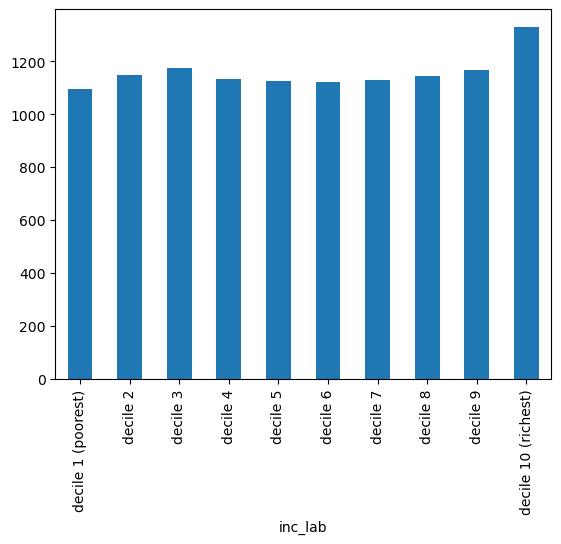

In [51]:
use_m2_total_inc = (use['netelectricity2019']*use['n_hhd']).groupby(level=0, sort=False).sum() #m2 total in each group summed by income level
use_cap_total_inc = use['n_hhdmem2019'].groupby(level=0, sort=False).sum() #no. of people in each group summed by income level
use_m2_per_cap_inc = use_m2_total_inc / use_cap_total_inc #m2/cap in each income group
use_m2_per_cap_inc.plot(kind='bar') #per person
"""interpretation: especially the highest income decile has considerably more electricity consumption than the vast majority"""

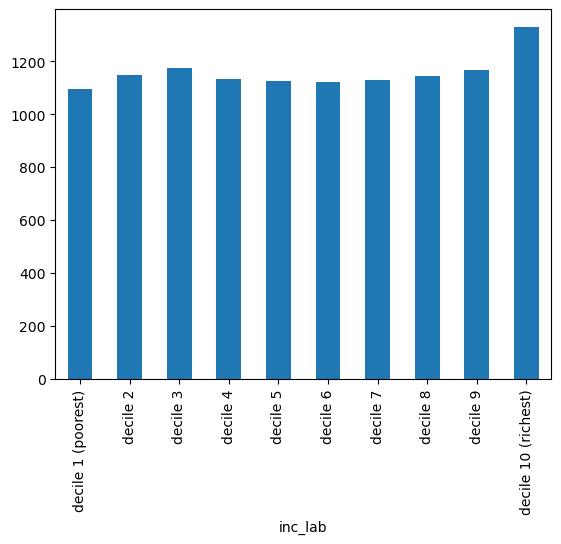

In [52]:
#floor area per income level
use_m2_total_inc = (use['netelectricity2019']*use['n_hhd']).groupby(level=0, sort=False).sum() #m2 total in each group summed by income level
use_cap_total_inc = use['n_hhdmem2019'].groupby(level=0, sort=False).sum() #no. of people in each group summed by income level
use_m2_per_cap_inc = use_m2_total_inc / use_cap_total_inc #m2/cap in each income group
use_m2_per_cap_inc.plot(kind='bar') #per person
"""interpretation: especially the highest income decile has considerably more floor area available than the vast majority"""

#floor area per income level and building type
use_m2_total_inc_type = (use['netelectricity2019']*use['n_hhd']).groupby(level=[0,1], sort=False).sum() #m2 total in each group summed by income level
use_cap_total_inc_type = use['n_hhdmem2019'].groupby(level=[0,1], sort=False).sum() #no. of people in each group summed by income level
use_m2_per_cap_inc_type = use_m2_total_inc_type / use_cap_total_inc_type #m2/cap in each income group

#preparing the dataframes for plotting
df = use_m2_per_cap_inc
df2=use_m2_per_cap_inc_type.rename('value').to_frame()
df2['n_hhd'] = use['n_hhd'].groupby(level=[0,1], sort=False).sum()
df2 = df2.reset_index()

#plot
colors = ['#000000', #construction
                            '#fe6100', #buildings                                              
                                        '#648fff', #roads
                                        '#785ef0', #railways
                                        '#ffb000', #electricity
                                        '#808080', #other civil engineering
                                        '#000000', #construction
                                        ]
fig = px.bar(df, x=df.values, y=df.index,  
             labels={'x':'kWh electricity use per capita', 'inc_lab':'household income level'}, 
             template='simple_white', 
             color_discrete_sequence=colors) 
fig.update_layout(width=1000, height=500, 
                      #xaxis_tickformat = '.0%',
                      font=dict(size=18),
                      bargap=0.9,
                      legend=dict(
        orientation="h",
        #entrywidth=70,
        yanchor="bottom",
        y=1.02,
        xanchor="left",
        x=-0.25,
    ))

df2=use_m2_per_cap_inc_type.rename('value').to_frame()
df2['n_hhd'] = use['n_hhd'].groupby(level=[0,1], sort=False).sum()

for i in df2.index.levels[1].to_list():
    df_plot = df2.xs(i, level=1)
    fig.add_trace(go.Scatter(
            y=df_plot.index, 
            x=df_plot['value'],
            mode='markers',
            name=i,
            marker=dict(size=df_plot['n_hhd'],
                        sizemode='area',
                        sizeref=4*max(df2['n_hhd'])/(40.**2),
                        sizemin=4,
                        #color=10*[0, 1, 2, 3],
                        ),
            showlegend=True
        ))

fig.write_image('visualisations/bubblechart_electricity_per_cap_inc_type.png', scale=3)
fig.show()


#### Mobility

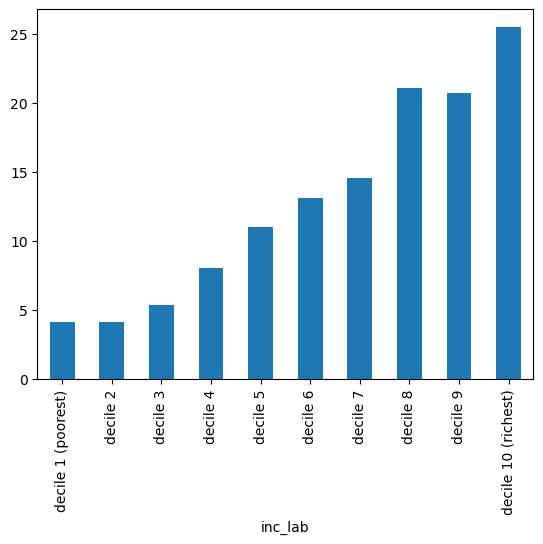

In [53]:
#floor area per income level
use_m2_total_inc = (use['car_pkm']*use['n_hhd']).groupby(level=0, sort=False).sum() #m2 total in each group summed by income level
use_cap_total_inc = use['n_hhdmem2019'].groupby(level=0, sort=False).sum() #no. of people in each group summed by income level
use_m2_per_cap_inc = use_m2_total_inc / use_cap_total_inc #m2/cap in each income group
use_m2_per_cap_inc.plot(kind='bar') #per person
"""interpretation: especially the highest income decile has considerably more floor area available than the vast majority"""

#floor area per income level and urbanisation type
use_m2_total_inc_type = (use['car_pkm']*use['n_hhd']).groupby(level=[0,3], sort=False).sum() #m2 total in each group summed by income level
use_cap_total_inc_type = use['n_hhdmem2019'].groupby(level=[0,3], sort=False).sum() #no. of people in each group summed by income level
use_m2_per_cap_inc_type = use_m2_total_inc_type / use_cap_total_inc_type #m2/cap in each income group

#preparing the dataframes for plotting
df = use_m2_per_cap_inc
df2=use_m2_per_cap_inc_type.rename('value').to_frame()
df2['n_hhd'] = use['n_hhd'].groupby(level=[0,3], sort=False).sum()

#plot
colors = ['#000000', #construction
                            '#fe6100', #buildings                                              
                                        '#648fff', #roads
                                        '#785ef0', #railways
                                        '#ffb000', #electricity
                                        '#808080', #other civil engineering
                                        '#000000', #construction
                                        ]
fig = px.bar(df, x=df.values, y=df.index,  
             labels={'x':'pkm car travel per capita', 'inc_lab':'household income level'}, 
             template='simple_white', 
             color_discrete_sequence=colors) 
fig.update_layout(width=1000, height=500, 
                      #xaxis_tickformat = '.0%',
                      font=dict(size=18),
                      bargap=0.9,
                      legend=dict(
        orientation="h",
        #entrywidth=70,
        yanchor="bottom",
        y=1.02,
        xanchor="left",
        x=-0.25,
    ))



for i in df2.index.levels[1].to_list():
    df_plot = df2.xs(i, level=1)
    fig.add_trace(go.Scatter(
            y=df_plot.index, 
            x=df_plot['value'],
            mode='markers',
            name=i,
            marker=dict(size=df_plot['n_hhd'],
                        sizemode='area',
                        sizeref=4*max(df2['n_hhd'])/(40.**2),
                        sizemin=4,
                        #color=10*[0, 1, 2, 3],
                        ),
            showlegend=True
        ))

fig.write_image('visualisations/bubblechart_carpkm_per_cap_inc_urb.png', scale=3)
fig.show()

'population density seems to be more indicative of car travel than the building type, although detached buildings are in each category more car travel intensive than multi-dwelling buildings of the same location'

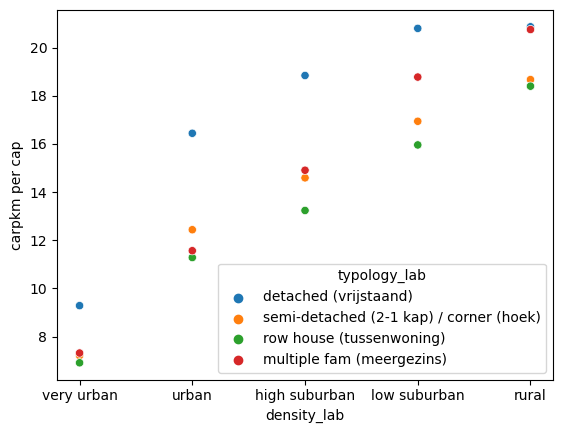

In [54]:
use_m2_total_inc = (use['car_pkm']*use['n_hhd']).groupby(level=[1,3], sort=False).sum() #m2 total in each group summed by income level
use_cap_total_inc = use['n_hhdmem2019'].groupby(level=[1,3], sort=False).sum() #no. of people in each group summed by income level
use_m2_per_cap_inc = use_m2_total_inc / use_cap_total_inc #m2/cap in each income group
use_m2_per_cap_inc
df_plot = use_m2_per_cap_inc.rename('carpkm per cap').reset_index()
sns.scatterplot(x='density_lab', y='carpkm per cap', data=df_plot, hue='typology_lab')
"""population density seems to be more indicative of car travel than the building type, although detached buildings are in each category more car travel intensive than multi-dwelling buildings of the same location"""

'the distance to the train station especially matters for car travel in rural and suburban areas, so low-density areas that are close to a train station have even lower car travel than urban areas that are close to such a station, whereas urban areas that are far from a train station still have low car travel'

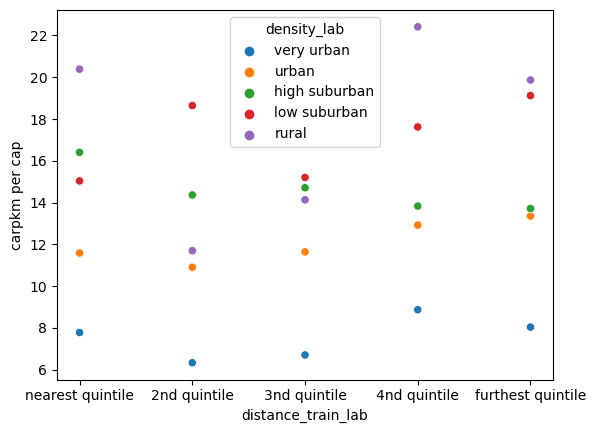

In [55]:
use_m2_total_inc = (use['car_pkm']*use['n_hhd']).groupby(level=[3,4], sort=False).sum() #m2 total in each group summed by income level
use_cap_total_inc = use['n_hhdmem2019'].groupby(level=[3,4], sort=False).sum() #no. of people in each group summed by income level
use_m2_per_cap_inc = use_m2_total_inc / use_cap_total_inc #m2/cap in each income group
use_m2_per_cap_inc
df_plot = use_m2_per_cap_inc.rename('carpkm per cap').reset_index()
sns.scatterplot(x='distance_train_lab', y='carpkm per cap', data=df_plot, hue='density_lab')
"""the distance to the train station especially matters for car travel in rural and suburban areas, so low-density areas that are close to a train station have even lower car travel than urban areas that are close to such a station, whereas urban areas that are far from a train station still have low car travel"""

### Building Construction
- translate floor space to BONSAI material categories
- include material use for maintenance
- normalise impact to annual using building lifetime

In [56]:
# Loading the material intensities per floor area
if material_buildings_source == "Oorschot-MPG": #kg/m2
    mi_buildings = pd.read_excel(
        "data_input/MI_Buildings_Oorschot2023MetabolicMPG.xlsx",
        sheet_name="Building_MI",
        index_col=[0, 1],
        header=[0, 1], skiprows=3
    ).drop("2018-2050", axis=0, level=1)
    mi_buildings.index.names = ["Building type", "Cohort"]
    mi_buildings.columns.names = ["BONSAI", "Material"]
    mi_buildings.fillna(0, inplace=True)
elif material_buildings_source == "Oorschot": #kg/m2
    mi_buildings = pd.read_excel(
        "data_input/MI_Buildings_Oorschot2023.xlsx",
        sheet_name="mi_pre2018",
        index_col=[0, 1],
        header=[0, 1],
    ).droplevel(1, axis=1)
    mi_buildings.index.names = ["Building type", "Cohort"]
    mi_buildings.columns.name = "Material"

    #converting the material intensities to BONSAI material categories
    mi_buildings_insulation_share = pd.read_excel(
            "data_input/MI_Buildings_Oorschot2023.xlsx",
            sheet_name="Share_of_insulation_materials",
            index_col=[0, 1],
            header=[0],
            skipfooter=3,
        ).drop("Unnamed: 8", axis=1)
    for i in mi_buildings_insulation_share.columns:
        mi_buildings[i] = (
            mi_buildings["Insulation"] * mi_buildings_insulation_share[i].iloc[0]
            )

    mi_buildings = (
            mi_buildings
            .T.groupby(level=0)
            .sum()
            .T.sort_index()
            .replace(0, np.nan)
            .dropna(how="all", axis=1)
            .drop("Insulation", axis=1)
        )
    # matching material names
    replacement_map = {'Bitumen':'Bitumen', #soon
                        'Brick':'Ceramics', #BRIK,
                        'Clay brick':'Ceramics', #BRIK
                        'Ceramics':'Ceramics', #BRIK (bricks, tiles, construction products)
                        'Sand-lime brick':'Ceramics', #BRIK
                        'Sand':'Sand', #SDCL
                        'Concrete':'Concrete', #CMNT (only lime,cement and plast, no mix)
                        'Mortal':'Mortar', #CMNT
                        'Gypsum':'Mortar', #CMNT (plaster of gypsum)
                        'Aluminum':'Aluminium', #ALUM
                        'Copper':'Copper', #COPP
                        'Other metals':'Other metals', #ONFM
                        'Electronics':'Electronics', #ELMA
                        'Glass':'Glass', #GLAS 
                        'Glass wool':'Glass', #GLAS (includes explicitely glass wool)
                        'Stone wool':'Mineral wool', #ONMM (includes explicitely mineral wool)
                        'Iron & steel':'Steel', #STEL or FABM
                        'Steel':'Steel', #STEL or FABM
                        'Other biobased materials':'Wood and straw', #WOOD
                        'Wood':'Wood and straw', #WOOD
                        'Other construction materials':'Other construction material', #ONMM, could also be STON, SDCL or CMNT
                        'Other':'Adhesives and paint', #could be CHEM, PLAS, PAPE, ELMA
                        'Paper':'Paper', #PAPE 
                        'Expanded polystyrene':'Plastic', #RUBP 
                        'Extruded polystyrene':'Plastic', #RUBP
                        'Plastic':'Plastic', #RUBP
                        'Plastics':'Plastic', #RUBP
                        'Polyurethanes':'Plastic', #RUBP
                        'Adhesives & paint':'Adhesives and paint', #CHEM (other chemical products, for glues) or PLAS (basic plastics) 
                        'Stone':'Stone', #STON
                        }

    mi_buildings = mi_buildings.stack().reset_index()
    mi_buildings['Material_group'] = mi_buildings['Material'].map(replacement_map)
    mi_buildings = mi_buildings.drop('Material', axis=1).groupby(['Building type', 'Cohort', 'Material_group']).sum().unstack().droplevel(0, axis=1)

    #selecting only residential buildings
    mi_buildings.drop(['industry', 'office', 'services', 'shop'], axis=0, level=0, inplace=True)




In [57]:
# visualisation of the assumed material intensities
""" the trend shows a shift from wood to brick and concrete"""
m_plot = mi_buildings.copy()
m_plot = m_plot.rename(index={'pre 1945':'1000-1945'})
if material_buildings_source == "Oorschot-MPG":
    m_plot = m_plot.groupby(axis=1, level=0).sum()
m_plot.index = [str(i) + ' ' + str(j) for i, j in m_plot.index]
m_plot = m_plot.stack().reset_index()
m_plot.columns = ['building', 'material', 'value']
fig = px.bar(m_plot, x='value', y='building', color='material', labels={'value':'material intensity per floor area [kg/m2]'}, template='simple_white', 
             color_discrete_sequence= px.colors.qualitative.Prism) #antique, vivid, prism, T10
fig.update_layout(width=1100, height=500, yaxis = dict(autorange="reversed"))    
fig.write_image('visualisations/mi_buildings'+material_buildings_source+'_grouped.svg')
fig.show()

In [58]:
#calculating the material contained in an average dwelling per category
mi_buildings.index = mi_buildings.index.rename(['typology_lab', 'const_lab']) # kg/m2 ufa
use_m2 = use['size2019_w1'].reorder_levels(['typology_lab', 'const_lab', 'inc_lab', "density_lab", "distance_train_lab"]) #m2 ufa / dwelling
use_m2 = pd.concat([use_m2] * len(mi_buildings.columns), axis=1)
use_m2.columns = mi_buildings.columns
material_buildings = use_m2.multiply(mi_buildings.reindex(use_m2.index), level=[0,1]) #kg / dwelling

In [59]:
material_buildings #kg / dwelling

BONSAI                                                                                            M_ALUM  \
Material                                                                               Aluminium (kg/m2)   
typology_lab              const_lab inc_lab             density_lab distance_train_lab                     
detached (vrijstaand)     pre 1945  decile 1 (poorest)  very urban  nearest quintile               21.65   
                                                                    2nd quintile                   20.18   
                                                                    3nd quintile                   20.27   
                                                                    4nd quintile                   34.81   
                                                                    furthest quintile                NaN   
...                                                                                                  ...   
multiple fam (meergezins) 2006-2022 decile 10 (richest) rural       nearest quintile              112.84   
                                                                    2nd quintile                  141.69   
                                                                    3nd quintile                  124.00   
                                                                    4nd quintile                  131.89   
                                                                    furthest quintile             124.64   

BONSAI                                                                                           M_BRIK  \
Material                                                                               Baksteen (kg/m2)   
typology_lab              const_lab inc_lab             density_lab distance_train_lab                    
detached (vrijstaand)     pre 1945  decile 1 (poorest)  very urban  nearest quintile          55,935.54   
                                                                    2nd quintile              52,144.73   
                                                                    3nd quintile              52,372.21   
                                                                    4nd quintile              89,929.35   
                                                                    furthest quintile               NaN   
...                                                                                                 ...   
multiple fam (meergezins) 2006-2022 decile 10 (richest) rural       nearest quintile           7,870.33   
                                                                    2nd quintile               9,881.96   
                                                                    3nd quintile               8,648.30   
                                                                    4nd quintile               9,198.70   
                                                                    furthest quintile          8,692.87   

BONSAI                                                                                 M_CMNT + M_SDCL  \
Material                                                                                 Beton (kg/m2)   
typology_lab              const_lab inc_lab             density_lab distance_train_lab                   
detached (vrijstaand)     pre 1945  decile 1 (poorest)  very urban  nearest quintile        265,429.68   
                                                                    2nd quintile            247,441.22   
                                                                    3nd quintile            248,520.70   
                                                                    4nd quintile            426,739.76   
                                                                    furthest quintile              NaN   
...                                                                                                ...   
multiple fam (meergezins) 2006-202

#### Environmental Footprint

In [60]:
# File import
mult_bonsai = pd.read_csv('data_input/240605_BONSAI_ghg_for_all_iluc.csv', index_col=[0,1,2,3], header=[0], skipfooter=9) # kg CO2eq. per kg material

#selecting relevant product codes
prod_codes = material_buildings.columns.levels[0].to_list()
prod_codes.append('M_CMNT')
mult_bonsai = mult_bonsai[mult_bonsai.index.get_level_values(0).isin(prod_codes)] 
mult_bonsai = mult_bonsai.droplevel([1,2,3])
mult_bonsai = mult_bonsai[['NL']] #select only NL market

#calculating environmental impacts of composite material concrete
concrete_cement_pc = 0.35 #based on M20 and M25 concrete grade
mult_bonsai.loc['M_CMNT + M_SDCL'] = mult_bonsai.loc[['M_CMNT']].squeeze()*concrete_cement_pc + mult_bonsai.loc[['M_SDCL']].squeeze()*(1-concrete_cement_pc)

mult_bonsai # kg CO2eq. per kg material

/var/folders/__/twfrdq8n75n5f0118_f882700000gn/T/ipykernel_23351/1297572943.py:2: ParserWarning:

Falling back to the 'python' engine because the 'c' engine does not support skipfooter; you can avoid this warning by specifying engine='python'.



,NL
Exio prod code,
M_STON,0.00
M_SDCL,0.00
M_WOOD,0.89
M_PAPE,2.43
M_BITU,1.79
M_CHEM,1.06
M_RUBP,3.79
M_GLAS,1.29
M_BRIK,0.18


In [61]:
# calculating embodied GHG emissions of materials in buildings
material_buildings_grouped = material_buildings.groupby(axis=1, level=0).sum() #kg/dwelling
ghg_material_buildings = material_buildings_grouped.multiply(mult_bonsai.iloc[:,0], axis=1).dropna(axis=1, how='all') #kg CO2eq. / dwelling

ghg_material_buildings #kg CO2eq/dwelling

M_ALUM  \
typology_lab              const_lab inc_lab             density_lab distance_train_lab           
detached (vrijstaand)     pre 1945  decile 1 (poorest)  very urban  nearest quintile    134.54   
                                                                    2nd quintile        125.42   
                                                                    3nd quintile        125.97   
                                                                    4nd quintile        216.30   
                                                                    furthest quintile     0.00   
...                                                                                        ...   
multiple fam (meergezins) 2006-2022 decile 10 (richest) rural       nearest quintile    701.17   
                                                                    2nd quintile        880.39   
                                                                    3nd quintile        770.48   
                                                                    4nd quintile        819.52   
                                                                    furthest quintile   774.45   

                                                                                        M_BITU  \
typology_lab              const_lab inc_lab             density_lab distance_train_lab           
detached (vrijstaand)     pre 1945  decile 1 (poorest)  very urban  nearest quintile      0.00   
                                                                    2nd quintile          0.00   
                                                                    3nd quintile          0.00   
                                                                    4nd quintile          0.00   
                                                                    furthest quintile     0.00   
...                                                                                        ...   
multiple fam (meergezins) 2006-2022 decile 10 (richest) rural       nearest quintile    212.71   
                                                                    2nd quintile        267.08   
                                                                    3nd quintile        233.73   
                                                                    4nd quintile        248.61   
                                                                    furthest quintile   234.94   

                                                                                          M_BRIK  \
typology_lab              const_lab inc_lab             density_lab distance_train_lab             
detached (vrijstaand)     pre 1945  decile 1 (poorest)  very urban  nearest quintile   21,677.92   
                                                                    2nd quintile       20,208.78   
                                                                    3nd quintile       20,296.94   
                                                                    4nd quintile       34,852.28   
                                                                    furthest quintile       0.00   
...                                                                                          ...   
multiple fam (meergezins) 2006-2022 decile 10 (richest) rural       nearest quintile   10,074.16   
                                                                    2nd quintile       12,649.08   
                                                                    3nd quintile       11,069.98   
                                                                    4nd quintile       11,774.49   
                                                                    furthest quintile  11,127.03   

                                                                                         M_CHEM  \
typology_lab              const_lab inc_lab             density_lab distance_train_lab            
detached (vrijstaand)     pre 1945  dec

In [62]:
ghg_material_buildings.sum(1) #total GHG emission per dwelling

typology_lab               const_lab  inc_lab              density_lab  distance_train_lab
detached (vrijstaand)      pre 1945   decile 1 (poorest)   very urban   nearest quintile     165,058.01
                                                                        2nd quintile         153,871.84
                                                                        3nd quintile         154,543.12
                                                                        4nd quintile         265,369.02
                                                                        furthest quintile          0.00
                                                                                                ...    
multiple fam (meergezins)  2006-2022  decile 10 (richest)  rural        nearest quintile     104,760.51
                                                                        2nd quintile         131,536.97
                                                                        3nd q

### Building Use Phase
- translate district heating to BONSAI fuel categories
- translate solar PV and heat pumps to BONSAI material categories
- harmonise labels for electricity and gas use with BONSAI categories

#### Electricity

In [63]:
# File import
mult_bonsai = pd.read_csv('data_input/240605_BONSAI_ghg_for_all_iluc.csv', index_col=[0,1,2,3], header=[0], skipfooter=9).droplevel([1,2,3]) # tonne CO2eq. per TJ electricity
mult_bonsai = mult_bonsai['NL'] #select only NL market

electricity_buildinguse = use['netelectricity2019'] #kWh per household per year
electricity_buildinguse = electricity_buildinguse * 3.6 #MJ per household per year
electricity_buildinguse = electricity_buildinguse /1e6 #TJ per household per year
ghg_electricity_buildinguse = electricity_buildinguse * mult_bonsai.loc['M_electricity'] * 1000 #kg CO2eq. per household per year

/var/folders/__/twfrdq8n75n5f0118_f882700000gn/T/ipykernel_23351/3670031071.py:2: ParserWarning:

Falling back to the 'python' engine because the 'c' engine does not support skipfooter; you can avoid this warning by specifying engine='python'.



In [64]:
ghg_electricity_buildinguse #annual GHG emission per household

inc_lab              typology_lab               const_lab  density_lab  distance_train_lab
decile 1 (poorest)   detached (vrijstaand)      pre 1945   very urban   nearest quintile     1,611.32
                                                                        2nd quintile         1,582.80
                                                                        3nd quintile         1,548.15
                                                                        4nd quintile         2,247.09
                                                                        furthest quintile         NaN
                                                                                               ...   
decile 10 (richest)  multiple fam (meergezins)  2006-2022  rural        nearest quintile     1,555.22
                                                                        2nd quintile         1,307.62
                                                                        3nd quintile         

#### Gas

In [65]:
#M_GASE upstream emissions of natural gas per tonne
#EF_GASE combustion of natural gas per TJ
gas_buildinguse = use['gas2019'] #m3 per household per year
gas_buildinguse_tonne = gas_buildinguse * 0.735 #kg per household per year
ghg_gas_buildinguse_footprint = gas_buildinguse_tonne * mult_bonsai.loc['M_GASE'] #kg CO2eq. per household per year
gas_buildinguse_GJ = gas_buildinguse * 0.0316 #GJ per household per year
ghg_gas_buildinguse_direct = gas_buildinguse_GJ * mult_bonsai.loc['EF_GASE'] #kg CO2eq. per household per year
ghg_gas_buildinguse = ghg_gas_buildinguse_footprint + ghg_gas_buildinguse_direct

In [66]:
ghg_gas_buildinguse #annual GHG emission per household

inc_lab              typology_lab               const_lab  density_lab  distance_train_lab
decile 1 (poorest)   detached (vrijstaand)      pre 1945   very urban   nearest quintile     5,118.57
                                                                        2nd quintile         5,345.68
                                                                        3nd quintile         5,404.29
                                                                        4nd quintile         6,155.29
                                                                        furthest quintile         NaN
                                                                                               ...   
decile 10 (richest)  multiple fam (meergezins)  2006-2022  rural        nearest quintile     1,947.86
                                                                        2nd quintile         2,701.50
                                                                        3nd quintile         

#### Other space heating (district heating)

In [67]:
ghg_heatpump_buildings = use['n_heatpump2019']*4614 #kg CO2e per heat pump (30kW) #TODO:remove info that this is from ecoinv

In [68]:
ghg_heatpump_buildings #annual GHG emission per household

inc_lab              typology_lab               const_lab  density_lab  distance_train_lab
decile 1 (poorest)   detached (vrijstaand)      pre 1945   very urban   nearest quintile     NaN
                                                                        2nd quintile         NaN
                                                                        3nd quintile         NaN
                                                                        4nd quintile         NaN
                                                                        furthest quintile    NaN
                                                                                              ..
decile 10 (richest)  multiple fam (meergezins)  2006-2022  rural        nearest quintile     NaN
                                                                        2nd quintile         NaN
                                                                        3nd quintile         NaN
                                    

In [69]:
#File import
district_heating = pd.read_excel(
    "data_input/District-Heating-Dataset.xlsx",
    sheet_name = "National average",
    header=[0],
)

energy_districtheating = use['n_cityheating2019']*use['warmteschatting_SW'] / use['n_hhd'] #GJ per household per year
district_heating.set_index('Heat_Source', inplace=True)
energy_districtheating_gas = (energy_districtheating * district_heating.loc['Gas power plant/cogeneration plant', 'Share']) * (mult_bonsai['A_CHP']) #kg CO2e of GJ combined heat and power plants
energy_districtheating_waste_biomass = (energy_districtheating * (district_heating.loc['Waste processing plant/incinerator', 'Share'] + district_heating.loc['Biomass power plant', 'Share'])) * (mult_bonsai['A_POWB']) #kg CO2e of GJ production of electricity by biomass and waste
energy_district_heating_rhindustry = (energy_districtheating *  district_heating.loc['Residual heat (industry)', 'Share'] + district_heating.loc['Biooil', 'Share']) * (mult_bonsai['M_heat_other']) #kg CO2e of GJ heat for industry not elsewhere specified 
energy_districtheating_boilers = (energy_districtheating * district_heating.loc['Peak gas boilers', 'Share']) * (mult_bonsai['EF_GASE']) #kg CO2e of GJ natural gas, combustion of
energy_districtheating_rhcoal = (energy_districtheating * district_heating.loc['Residual heat (coal)', 'Share']) * (mult_bonsai['A_POWC']) #kg CO2e of GJ production of electricity by coal
energy_districtheating_biogas = (energy_districtheating * district_heating.loc['Biogas', 'Share']) * (mult_bonsai['EF_MBIO']) #kg CO2e of GJ Biogas, combustion of
#ghg_heat_districtheating = energy_districtheating * mult_bonsai['M_heat_HOUS'] #kg CO2eq. per household per year
ghg_heat_districtheating = energy_districtheating_gas + energy_districtheating_waste_biomass + energy_district_heating_rhindustry + energy_districtheating_boilers + energy_districtheating_rhcoal + energy_districtheating_biogas

ghg_heat_districtheating

inc_lab              typology_lab               const_lab  density_lab  distance_train_lab
decile 1 (poorest)   detached (vrijstaand)      pre 1945   very urban   nearest quintile     NaN
                                                                        2nd quintile         NaN
                                                                        3nd quintile         NaN
                                                                        4nd quintile         NaN
                                                                        furthest quintile    NaN
                                                                                              ..
decile 10 (richest)  multiple fam (meergezins)  2006-2022  rural        nearest quintile     NaN
                                                                        2nd quintile         NaN
                                                                        3nd quintile         NaN
                                    

In [70]:
capacity_photovoltaic = use['solarcapacity2019'] #kWp PV per household (including households with and without) 
ghg_material_photovoltaic = capacity_photovoltaic/3 * 6313 #kg CO2eq. per household #TODO:remove info that this is from ecoinv

In [71]:
(use['solarcapacity2019']*use['n_hhd']/(use['n_solar2019'].fillna(2.5)))/ 3 #kWp per household with 

inc_lab              typology_lab               const_lab  density_lab  distance_train_lab
decile 1 (poorest)   detached (vrijstaand)      pre 1945   very urban   nearest quintile     0.35
                                                                        2nd quintile         1.99
                                                                        3nd quintile         3.68
                                                                        4nd quintile         0.00
                                                                        furthest quintile     NaN
                                                                                             ... 
decile 10 (richest)  multiple fam (meergezins)  2006-2022  rural        nearest quintile     0.00
                                                                        2nd quintile         1.34
                                                                        3nd quintile         1.37
                           

### Mobility
- add pkm and cars to use data
- translate pkm to BONSAI fuel categories
- translate pkm to infrastructure demand to BONSAI material categories
- normalise cars to annual cars using car lifetime
- harmonise labels for cars with BONSAI categories

In [72]:
#TODO: update emission factors below to NL context (these are currently sourced from Allekotte et al. 2020 for German context) #data also allows for distinguishing use phase, infrastructure and vehicle emission 
#ghg_car_mobilityuse = use['car_pkm']*158/1000 #kg CO2eq. per household per year (including use phase, infrastructure; excluding: vehicle production)
ghg_car_mobilityuse = use['car_pkm']*0.36599 #kg CO2eq (including use phase, infrastructure and vehicle production); Ecoinvent (market for transport, passenger car, Europe (RER)); CMLv4.8 2016
ghg_car_vehicle = use['car_hhd']*mult_bonsai.loc['M_auto']*1000 #kg CO2eq. per household per year
ghg_transit_mobilityuse = (use['transit_pkm']*0.7)*0.044621 + (use['transit_pkm']*0.3)*0.11334 #kg CO2eq (including use phase, infrastructure, and vehicle production); Ecoinvent (transport, passenger, train (Italy) and transport, regular bus (Switzerland)); CMLv4.8 2016
#source for ghg_transit share pkm: https://ec.europa.eu/eurostat/statistics-explained/index.php?title=File:Travel_distance_per_person_per_day_by_main_travel_mode_for_urban_mobility_on_all_days_(%25)_v3.png ; https://opendata.cbs.nl/statline/#/CBS/en/dataset/84687ENG/table 
#ghg_transit_mobilityuse = use['transit_pkm']*73/1000 #kg CO2eq. per household per year (including use phase, infrastructure and vehicle production)
#ghg_cycle_mobilityuse = use['cycle_pkm']*11/1000 #kg CO2eq. per household per year (including infrastructure and vehicle production)
ghg_cycle_mobilityuse = use['cycle_pkm']*0.0011864 #kg CO2eq (including infrastructure and vehicle produciton); Ecoinvent (transport, passenter, bicycle, Switzerland); CMLv4.8 2016

## Background System: Environmental Footprints

## GHG summary

In [73]:
#source for lifetimes: https://www.oecd-ilibrary.org/docserver/d07136f0-en.pdf?expires=1729253351&id=id&accname=guest&checksum=36E59B772FE676213DBDE7CA1CA5B3D3 
#TODO: impelemnt material specific lifetimes for the buildings to include maintenance material flows
lifetime_building = 80 #years
lifetime_photovoltaic = 30 #years
lifetime_heatpump = 20 #years
lifetime_car = 10 #years


ghg_annual = pd.concat([
    (ghg_material_buildings.sum(1)/lifetime_building).reorder_levels([2,0,1,3,4]).rename('ghg_material_buildings'), 
    (ghg_heatpump_buildings/lifetime_heatpump).rename('ghg_material_heatpump'), 
    ghg_heat_districtheating.rename('ghg_heat_districtheating'),
    ghg_gas_buildinguse.rename('ghg_gas_buildinguse'), 
    ghg_electricity_buildinguse.rename('ghg_electricity_buildinguse'), 
    (ghg_material_photovoltaic/lifetime_photovoltaic).rename('ghg_material_photovoltaic'),
    ghg_car_mobilityuse.rename('ghg_car_mobilityuse'), 
    #(ghg_car_vehicle/lifetime_car).rename('ghg_car_vehicle'),
    ghg_transit_mobilityuse.rename('ghg_transit_mobilityuse'), 
    ghg_cycle_mobilityuse.rename('ghg_cycle_mobilityuse'), 
    ], axis=1)

In [74]:
ghg_annual.sum(0) #TODO: check again if gas emission factors make sense! and if District heating and electricy use makes sense; lower emissions than bicycle use?

ghg_material_buildings         7,327,301.88
ghg_material_heatpump            843,208.50
ghg_heat_districtheating          41,351.51
ghg_gas_buildinguse           16,899,046.19
ghg_electricity_buildinguse    7,283,982.02
ghg_material_photovoltaic        208,738.49
ghg_car_mobilityuse               68,626.79
ghg_transit_mobilityuse              579.94
ghg_cycle_mobilityuse                 18.90
dtype: float64

In [75]:
    df = ghg_annual.multiply(use['n_hhd'], axis=0).groupby(level=0, sort=False).sum().unstack().reset_index()
    df.columns = ['process', 'income level', 'value']

    fig = px.bar(df, x='value', y='income level',color='process', 
                 #text=df['percentage'].apply(lambda x: '{0:.1%}'.format(x)), 
                 #labels={'value':'Carbon footprint of EU construction in '+str(iot_year)+' [Mt CO<sub>2</sub>]', 'subsector':''}, 
                 template='simple_white', 
             color_discrete_sequence=px.colors.qualitative.Vivid) 
    #fig.update_traces(textposition='inside')
    fig.update_layout(width=1000, height=500, 
                      #xaxis_tickformat = '.0%',
                      font=dict(size=18),
                      legend=dict(
        orientation="h",
        #entrywidth=70,
        yanchor="bottom",
        y=1.02,
        xanchor="left",
        x=-0.25
    ))
    fig.update_traces(marker_line_width=0)

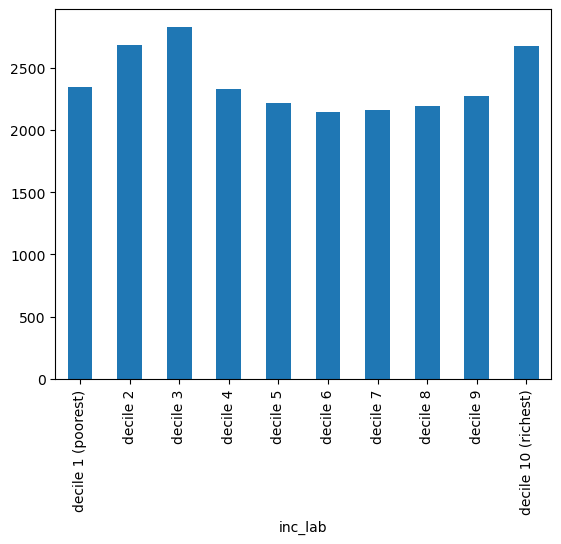

In [76]:
#floor area per income level
use_m2_total_inc = (ghg_annual.sum(1)*use['n_hhd']).groupby(level=0, sort=False).sum() #m2 total in each group summed by income level
use_cap_total_inc = use['n_hhdmem2019'].groupby(level=0, sort=False).sum() #no. of people in each group summed by income level
use_m2_per_cap_inc = use_m2_total_inc / use_cap_total_inc #m2/cap in each income group
use_m2_per_cap_inc.plot(kind='bar') #per person
"""interpretation: especially the highest income decile has considerably more floor area available than the vast majority"""

#floor area per income level and building type
use_m2_total_inc_type = (ghg_annual.sum(1)*use['n_hhd']).groupby(level=[0,1], sort=False).sum() #m2 total in each group summed by income level
use_cap_total_inc_type = use['n_hhdmem2019'].groupby(level=[0,1], sort=False).sum() #no. of people in each group summed by income level
use_m2_per_cap_inc_type = use_m2_total_inc_type / use_cap_total_inc_type #m2/cap in each income group

#preparing the dataframes for plotting
df = use_m2_per_cap_inc
df2=use_m2_per_cap_inc_type.rename('value').to_frame()
df2['n_hhd'] = use['n_hhd'].groupby(level=[0,1], sort=False).sum()
df2 = df2.reset_index()

#plot
colors = ['#000000', #construction
                            '#fe6100', #buildings                                              
                                        '#648fff', #roads
                                        '#785ef0', #railways
                                        '#ffb000', #electricity
                                        '#808080', #other civil engineering
                                        '#000000', #construction
                                        ]
fig = px.bar(df, x=df.values, y=df.index,  
             labels={'x':'kg CO2eq. per capita', 'inc_lab':'household income level'}, 
             template='simple_white', 
             color_discrete_sequence=colors) 
fig.update_layout(width=1000, height=500, 
                      #xaxis_tickformat = '.0%',
                      font=dict(size=18),
                      bargap=0.9,
                      legend=dict(
        orientation="h",
        #entrywidth=70,
        yanchor="bottom",
        y=1.02,
        xanchor="left",
        x=-0.25,
    ))

df2=use_m2_per_cap_inc_type.rename('value').to_frame()
df2['n_hhd'] = use['n_hhd'].groupby(level=[0,1], sort=False).sum()

for i in df2.index.levels[1].to_list():
    df_plot = df2.xs(i, level=1)
    fig.add_trace(go.Scatter(
            y=df_plot.index, 
            x=df_plot['value'],
            mode='markers',
            name=i,
            marker=dict(size=df_plot['n_hhd'],
                        sizemode='area',
                        sizeref=4*max(df2['n_hhd'])/(40.**2),
                        sizemin=4,
                        #color=10*[0, 1, 2, 3],
                        ),
            showlegend=True
        ))
fig.update_traces(marker_line_width=0)
fig.write_image('visualisations/bubblechart_ghg_per_cap_inc_type.png', scale=3)
fig.show()

In [77]:
use

inc_decile  \
inc_lab             typology_lab              const_lab density_lab distance_train_lab               
decile 1 (poorest)  detached (vrijstaand)     pre 1945  very urban  nearest quintile             1   
                                                                    2nd quintile                 1   
                                                                    3nd quintile                 1   
                                                                    4nd quintile                 1   
                                                                    furthest quintile            1   
...                                                                                            ...   
decile 10 (richest) multiple fam (meergezins) 2006-2022 rural       nearest quintile            10   
                                                                    2nd quintile                10   
                                                                    3nd quintile                10   
                                                                    4nd quintile                10   
                                                                    furthest quintile           10   

                                                                                        typology4_2019  \
inc_lab             typology_lab              const_lab density_lab distance_train_lab                   
decile 1 (poorest)  detached (vrijstaand)     pre 1945  very urban  nearest quintile                 1   
                                                                    2nd quintile                     1   
                                                                    3nd quintile                     1   
                                                                    4nd quintile                     1   
                                                                    furthest quintile                1   
...                                                                                                ...   
decile 10 (richest) multiple fam (meergezins) 2006-2022 rural       nearest quintile                 4   
                                                                    2nd quintile                     4   
                                                                    3nd quintile                     4   
                                                                    4nd quintile                     4   
                                                                    furthest quintile                4   

                                                                                        const_cat2019  \
inc_lab             typology_lab              const_lab density_lab distance_train_lab                  
decile 1 (poorest)  detached (vrijstaand)     pre 1945  very urban  nearest quintile                1   
                                                                    2nd quintile                    1   
                                                                    3nd quintile                    1   
                                                                    4nd quintile                    1   
                                                                    furthest quintile               1   
...                                                                                               ...   
decile 10 (richest) multiple fam (meergezins) 2006-2022 rural       nearest quintile                6   
                                                                    2nd quintile                    6   
                                                                    3nd quintile                    6   
                                                                    4nd quintile                    6   
                                                                    furthest quintile               6   

                

In [78]:
#df = use[['inc_decile','size2019_w1', 'gas2019', 'n_heatpump2019','netelectricity2019', 'car_pkm']].reset_index()
sns.pairplot(df, hue="density_lab", kind="reg", plot_kws={'scatter_kws': {'alpha': 0.1}})

TypeError: 'data' must be pandas DataFrame object, not: <class 'pandas.core.series.Series'>

# CODE ARCHIVE

In [ ]:
# Configurations
mi_buildings_source = "Oorschot"  # Oorschot or Yang
# Load data
if mi_buildings_source == "Oorschot":
    mi_buildings = pd.read_excel(
        "data_input/MI_Buildings_Oorschot2023.xlsx",
        sheet_name="MI_2018",
        index_col=[0, 1],
        header=[0, 1],
    ).droplevel(1, axis=1)
    mi_buildings.index.names = ["Building type", "Cohort"]
    mi_buildings.columns.name = "Material"

    mi_buildings_2018 = pd.read_excel(
        "data_input/MI_Buildings_Oorschot2023.xlsx",
        sheet_name="MI_2018-2050",
        index_col=[0],
        header=[0, 1],
        skipfooter=20,
    ).droplevel(1, axis=1)
    mi_buildings_2018["Cohort"] = "2018"
    mi_buildings_2018.reset_index(inplace=True)
    mi_buildings_2018["index"] = [i.lower() for i in mi_buildings_2018["index"]]
    mi_buildings_2018.set_index(["index", "Cohort"], inplace=True)
    mi_buildings_2018.index.names = ["Building type", "Cohort"]
    mi_buildings_2018.columns.name = "Material"

    mi_buildings_insulation_share = pd.read_excel(
        "data_input/MI_Buildings_Oorschot2023.xlsx",
        sheet_name="Share_of_insulation_materials",
        index_col=[0, 1],
        header=[0],
        skipfooter=3,
    ).drop("Unnamed: 8", axis=1)
    for i in mi_buildings_insulation_share.columns:
        mi_buildings[i] = (
            mi_buildings["Insulation"] * mi_buildings_insulation_share[i].iloc[0]
        )
        mi_buildings_2018[i] = (
            mi_buildings_2018["Insulation"] * mi_buildings_insulation_share[i].iloc[1]
        )

    mi_buildings = (
        pd.concat([mi_buildings, mi_buildings_2018], axis=1)
        .T.groupby(level=0)
        .sum()
        .T.sort_index()
        .replace(0, np.nan)
        .dropna(how="all", axis=1)
        .drop("Insulation", axis=1)
    )

# matching material names
replacement_map = {'Bitumen':'Bitumen', #soon
                    'Brick':'Ceramics', #BRIK,
                    'Clay brick':'Ceramics', #BRIK
                    'Ceramics':'Ceramics', #BRIK (bricks, tiles, construction products)
                    'Sand-lime brick':'Ceramics', #BRIK
                    'Sand':'Sand', #SDCL
                    'Concrete':'Concrete', #CMNT (only lime,cement and plast, no mix)
                    'Mortal':'Mortar', #CMNT
                    'Gypsum':'Mortar', #CMNT (plaster of gypsum)
                    'Aluminum':'Aluminium', #ALUM
                    'Copper':'Copper', #COPP
                    'Other metals':'Other metals', #ONFM
                    'Electronics':'Electronics', #ELMA
                    'Glass':'Glass', #GLAS 
                    'Glass wool':'Glass', #GLAS (includes explicitely glass wool)
                    'Stone wool':'Mineral wool', #ONMM (includes explicitely mineral wool)
                    'Iron & steel':'Steel', #STEL or FABM
                    'Steel':'Steel', #STEL or FABM
                    'Other biobased materials':'Wood and straw', #WOOD
                    'Wood':'Wood and straw', #WOOD
                    'Other construction materials':'Other construction material', #ONMM, could also be STON, SDCL or CMNT
                    'Other':'Adhesives and paint', #could be CHEM, PLAS, PAPE, ELMA
                    'Paper':'Paper', #PAPE 
                    'Expanded polystyrene':'Plastic', #RUBP 
                    'Extruded polystyrene':'Plastic', #RUBP
                    'Plastic':'Plastic', #RUBP
                    'Plastics':'Plastic', #RUBP
                    'Polyurethanes':'Plastic', #RUBP
                    'Adhesives & paint':'Adhesives and paint', #CHEM (other chemical products, for glues) or PLAS (basic plastics) 
                    'Stone':'Stone', #STON
                    }

mi_buildings = mi_buildings.stack().reset_index()
mi_buildings['Material_group'] = mi_buildings['Material'].map(replacement_map)
mi_buildings.replace('<1945','1944', inplace=True)
mi_buildings = mi_buildings.drop('Material', axis=1).groupby(['Building type', 'Cohort', 'Material_group']).sum().unstack().droplevel(0, axis=1)

#selecting only residential buildings
mi_buildings.drop(['industry', 'office', 'services', 'shop'], axis=0, level=0, inplace=True)

TypeError: can't multiply sequence by non-int of type 'float'

In [ ]:
# Configurations
ei_heating_source = "TABULA"  # Oorschot or Yang
# Load data
if ei_heating_source == "TABULA":
    ei_heating = pd.read_excel(
        "data_input/EI_Heating_HotWater_TABULA2017.xlsx",
        sheet_name="0_EnergyDemandIntensity",
        index_col=[0],
        header=[0],
    ).drop('Default Heating & Hot Water', axis=1)

In [ ]:
m_plot = ei_heating.copy()

m_plot = m_plot.stack().reset_index()
m_plot.columns = ['building', 'function', 'value']
fig = px.bar(m_plot, x='value', y='building', color='function', labels={'value':'energy intensity per floor area [kWh/m2]'}, template='simple_white', 
             color_discrete_sequence= px.colors.qualitative.Prism) #antique, vivid, prism, T10
fig.update_layout(width=500, height=1200, yaxis = dict(autorange="reversed"))    
fig.write_image('visualisations/ei_heating'+ei_heating_source+'.svg')
fig.show()

In [ ]:
# Configurations
mi_buildings_source = "Yang"  # Oorschot or Yang
# Load data
if mi_buildings_source == "Yang":
    mi_buildings = pd.read_excel(
        "data_input/MI_Buildings_Yang2022.xlsx",
        sheet_name='0_MaterialIntensity',
        index_col=[0, 1],
        header=[0, 1],
    ).droplevel(0, axis=0).droplevel(1, axis=1)
    mi_buildings.index.names = ["Building type"]
    mi_buildings.columns.name = "Material"

    # matching material names
    replacement_map = {'bitumen adhesive compound, hot':'Bitumen', #soon
                        'clay brick':'Ceramics', #BRIK
                        'ceramic tile':'Ceramics', #BRIK (bricks, tiles, construction products)
                        'sand':'Sand', #SDCL
                        'concrete, normal':'Concrete', #CMNT (only lime,cement and plast, no mix)
                        'fibre-reinforced concrete':'Concrete', #CMNT (only lime,cement and plast, no mix)
                        'cement mortar':'Mortar', #CMNT
                        'gypsum, mineral':'Mortar', #CMNT (plaster of gypsum)
                        'aluminium, wrought alloy':'Aluminium', #ALUM ##
                        'copper':'Copper', #COPP
                        'zinc':'Zinc', #LZNC
                        'flat glass, coated':'Glass', #GLAS 
                        'glass wool mat':'Glass', #GLAS (includes explicitely glass wool)
                        'cast iron':'Steel', #STEL or FABM
                        'wire drawing, steel':'Steel', #STEL or FABM
                        'plywood, for indoor use':'Wood and straw', #WOOD
                        'sawnwood, hardwood, raw':'Wood and straw', #WOOD
                        'sawnwood, softwood, raw':'Wood and straw', #WOOD
                        'fibreboard, soft':'Wood and straw', #WOOD
                        'polystyrene, expandable':'Plastic', #RUBP 
                        'polystyrene, extruded':'Plastic', #RUBP
                        'extrusion, plastic pipes':'Plastic', #RUBP
                        'polyurethane, flexible foam':'Plastic', #RUBP
                        'gravel, crushed':'Stone', #STON
                        'argon, liquid':'Argon', #CHEM
                        }

    mi_buildings = mi_buildings.stack().reset_index()
    mi_buildings['Material_group'] = mi_buildings['Material'].map(replacement_map)
    mi_buildings = mi_buildings.drop('Material', axis=1).groupby(['Building type', 'Material_group']).sum().unstack().droplevel(0, axis=1)

    nzeb = mi_buildings.loc[(mi_buildings.index.str.contains('_NZEB')) & ~(mi_buildings.index.str.contains('new'))]
    nzeb.index = [i[:-5] for i in nzeb.index]
    nzeb = nzeb + mi_buildings.loc[~(mi_buildings.index.str.contains('_NZEB')) & ~(mi_buildings.index.str.contains('new'))]
    nzeb.index = [i+'_NZEB' for i in nzeb.index]
    mi_buildings.update(nzeb)

In [ ]:
m_plot = mi_buildings[~mi_buildings.duplicated()]
m_plot = m_plot.stack().reset_index()
m_plot.columns = ['building', 'material', 'value']
fig = px.bar(m_plot, x='value', y='building', color='material', labels={'value':'material intensity per floor area [kg/m2]', 'sector':'Input sector'}, template='simple_white', 
             color_discrete_sequence= px.colors.qualitative.Prism) #antique, vivid, prism, T10
fig.update_layout(width=1100, height=700, yaxis = dict(autorange="reversed"))    
fig.write_image('visualisations/mi_buildings'+mi_buildings_source+'.svg')
fig.show()